In [1]:
#===========================================
# IMPORT LIBRARIES
#===========================================


import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Machine Learning
from sklearn.model_selection import train_test_split
from sklearn.model_selection import cross_val_score

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    roc_auc_score,
    classification_report
)

# Ignore warnings
import warnings
warnings.filterwarnings("ignore")

In [2]:
#=====================================================================================================
# LOAD DATASETS
#=====================================================================================================
import os
os.chdir(r"C:\Users\Admin\OneDrive - Sol Plaatje University\Documents\Capstone project")


df_outbreaks = pd.read_csv("fmd_outbreaks.csv", skiprows=12)

df_temp = pd.read_csv(
    "climate_rain.csv",
    sep=";",
    decimal=","
)

df_livestock = pd.read_csv("livestock_stocks.csv")

In [3]:
print(df_outbreaks.head())

   Event.ID       Global.ID                 Disease Serotype  Region  \
0     52301  UNFAO-HQ-52301  Foot and mouth disease     SAT1  Africa   
1     52255  UNFAO-HQ-52255  Foot and mouth disease     SAT1  Africa   
2     52283  UNFAO-HQ-52283  Foot and mouth disease     SAT1  Africa   
3     52285  UNFAO-HQ-52285  Foot and mouth disease     SAT1  Africa   
4     52286  UNFAO-HQ-52286  Foot and mouth disease     SAT1  Africa   

         Subregion       Country Admin.level.1                     Locality  \
0  Southern Africa  South Africa       Gauteng  192389FMD_GAU_SAT1_2025_643   
1  Southern Africa  South Africa           NaN  192339FMD_GAU_SAT1_2025_639   
2  Southern Africa  South Africa    Free State  192331FMD_GAU_SAT1_2025_636   
3  Southern Africa  South Africa           NaN  192334FMD_GAU_SAT1_2025_637   
4  Southern Africa  South Africa           NaN  192337FMD_GAU_SAT1_2025_638   

   Latitude  Longitude   Diagnosis.source Diagnosis.status        Animal.type  \
0     -26.5

In [4]:
print(df_outbreaks.shape)

(2800, 19)


In [5]:
print(df_temp.head())

           code           name  1901-01  1901-02  1901-03  1901-04  1901-05  \
0   ZAF.2272707     Free State    62.38   114.03   124.73    47.61     2.59   
1   ZAF.2272708        Gauteng   124.66    74.36   126.83    50.45     2.47   
2   ZAF.2272714   Western Cape    28.32    64.21    23.67    34.31    72.36   
3  ZAF.22777310   Eastern Cape    29.21   107.43    74.98    51.62    15.80   
4  ZAF.22777311  KwaZulu-Natal   140.63   126.14   131.61    67.85    24.43   

   1901-06  1901-07  1901-08  ...  2025-03  2025-04  2025-05  2025-06  \
0     6.44     4.10    18.04  ...    74.76    59.56    18.82     6.03   
1     2.16     1.68    10.38  ...    77.61    73.11    12.73     4.35   
2    20.34    38.67    15.42  ...    34.58    40.31    38.95    53.93   
3    20.67    11.08    22.21  ...    83.16    47.72    29.99    27.84   
4    36.66    14.32    52.52  ...    82.16    58.97    23.70     9.40   

   2025-07  2025-08  2025-09  2025-10  2025-11  2025-12  
0     6.59    13.02    63.14

In [6]:
print(df_temp.shape)

(9, 1502)


In [7]:
print(df_livestock.head())

  Domain Code                        Domain  Area Code (M49)          Area  \
0         QCL  Crops and livestock products              710  South Africa   
1         QCL  Crops and livestock products              710  South Africa   
2         QCL  Crops and livestock products              710  South Africa   
3         QCL  Crops and livestock products              710  South Africa   
4         QCL  Crops and livestock products              710  South Africa   

   Element Code Element  Item Code (CPC)    Item  Year Code  Year Unit  \
0          5111  Stocks             2111  Cattle       2005  2005   An   
1          5111  Stocks             2111  Cattle       2006  2006   An   
2          5111  Stocks             2111  Cattle       2007  2007   An   
3          5111  Stocks             2111  Cattle       2008  2008   An   
4          5111  Stocks             2111  Cattle       2009  2009   An   

      Value Flag Flag Description  Note  
0  13790000    A  Official figure   NaN  
1 

In [8]:
print(df_livestock.shape)

(60, 15)


In [9]:
df_outbreaks.isnull().sum()

Event.ID                            0
Global.ID                           0
Disease                             0
Serotype                           12
Region                              0
Subregion                           0
Country                             0
Admin.level.1                     604
Locality                            0
Latitude                            0
Longitude                           0
Diagnosis.source                    0
Diagnosis.status                    0
Animal.type                         0
Species                             0
Observation.date..dd.mm.yyyy.       2
Report.date..dd.mm.yyyy.            0
Humans.affected                  2800
Human.deaths                     2800
dtype: int64

In [10]:
df_temp.isnull().sum()

code       0
name       0
1901-01    0
1901-02    0
1901-03    0
          ..
2025-08    0
2025-09    0
2025-10    0
2025-11    0
2025-12    0
Length: 1502, dtype: int64

In [11]:
df_livestock.isnull().sum()

Domain Code          0
Domain               0
Area Code (M49)      0
Area                 0
Element Code         0
Element              0
Item Code (CPC)      0
Item                 0
Year Code            0
Year                 0
Unit                 0
Value                0
Flag                 0
Flag Description     0
Note                60
dtype: int64

In [12]:
#CLEANING OUTBREAK DATASET

woah = df_outbreaks.copy()

woah = woah[
    [
        'Admin.level.1',
        'Latitude',
        'Longitude',
        'Observation.date..dd.mm.yyyy.'
    ]
]


In [13]:
woah.head()

,Admin.level.1,Latitude,Longitude,Observation.date..dd.mm.yyyy.
0,Gauteng,-26.5,27.5,08/07/2026
1,NaN,-28.1,25.2,07/07/2026
2,Free State,-29.1,26.4,07/07/2026
3,NaN,-28.6,25.5,07/07/2026
4,NaN,-28.6,25.3,07/07/2026


In [14]:
woah = woah.rename(columns={
    'Admin.level.1': 'Province',
    'Observation.date..dd.mm.yyyy.': 'Observation_Date',
    'Report.date..dd.mm.yyyy.': 'Report_Date'
})

In [15]:
#==================================================================================================================
# Spatial Join
#==================================================================================================================
import geopandas as gpd
#Read the shapefile:
map_path = r"C:\Users\Admin\OneDrive - Sol Plaatje University\Documents\Capstone project\datasets\gadm41_ZAF_2.shp"
south_africa = gpd.read_file(map_path)
#Creating geographic points from the outbreak coordinates:
woah_geo = gpd.GeoDataFrame(
    woah,
    geometry=gpd.points_from_xy(
        woah.Longitude,
        woah.Latitude
    ),
    crs="EPSG:4326"
)

In [16]:

#Making sure both datasets use the same coordinate system:
south_africa = south_africa.to_crs(woah_geo.crs)

In [17]:
#Performing the spatial join:
woah_geo = gpd.sjoin(
    woah_geo,
    south_africa[['NAME_1', 'NAME_2', 'geometry']],
    how='left',
    predicate='within'
)

In [18]:
#Then filling in the missing provinces
woah_geo['Province'] = woah_geo['Province'].fillna(woah_geo['NAME_1'])
woah_geo['Province'].isnull().sum()

0

In [19]:
woah_geo[['Province', 'Latitude', 'Longitude']].head(10)

,Province,Latitude,Longitude
0,Gauteng,-26.5,27.5
1,Free State,-28.1,25.2
2,Free State,-29.1,26.4
3,Free State,-28.6,25.5
4,Free State,-28.6,25.3
5,North West,-26.3,24.4
6,North West,-26.5,24.1
7,North West,-27.7,24.5
8,Northern Cape,-26.9,23.7
9,Eastern Cape,-31.2,28.6


In [20]:
# Convert Observation_Date to datetime
# and  Extract the Year
woah_geo['Observation_Date'] = pd.to_datetime(
    woah_geo['Observation_Date'],
    dayfirst=True
)

woah_geo['Year'] = woah_geo['Observation_Date'].dt.year

In [21]:
woah_geo = woah_geo[
    (woah_geo['Year'] >= 2005) &
    (woah_geo['Year'] <= 2024)
]

In [22]:
print(woah_geo['Year'].min())
print(woah_geo['Year'].max())

2006.0
2024.0


In [23]:
# Extract Month from the observation date
woah_geo['Month'] = woah_geo['Observation_Date'].dt.month

# Creating monthly outbreak summary
outbreak_summary = (
    woah_geo
    .groupby(['Province', 'Year', 'Month'])
    .size()
    .reset_index(name='Outbreak_Count')
)

# Binary target
outbreak_summary['Outbreak'] = (
    outbreak_summary['Outbreak_Count'] > 0
).astype(int)

print(outbreak_summary.head(10))
print(outbreak_summary.shape)

       Province    Year  Month  Outbreak_Count  Outbreak
0  Eastern Cape  2022.0     10               1         1
1  Eastern Cape  2024.0      4               5         1
2  Eastern Cape  2024.0      5               5         1
3  Eastern Cape  2024.0      6              16         1
4  Eastern Cape  2024.0      7              10         1
5  Eastern Cape  2024.0      8               2         1
6  Eastern Cape  2024.0      9               3         1
7    Free State  2021.0      9               2         1
8    Free State  2022.0      6               2         1
9    Free State  2022.0      7              16         1
(102, 5)


In [24]:
#rainfall dataset
rain_monthly = df_temp.melt(
    id_vars=['code', 'name'],
    var_name='Date',
    value_name='Rainfall'
)

# Split Year and Month
rain_monthly[['Year','Month']] = rain_monthly['Date'].str.split('-', expand=True)

rain_monthly['Year'] = rain_monthly['Year'].astype(int)
rain_monthly['Month'] = rain_monthly['Month'].astype(int)

# Rename
rain_monthly = rain_monthly.rename(columns={
    'name':'Province'
})

#  years
rain_monthly = rain_monthly[
    (rain_monthly['Year']>=2005) &
    (rain_monthly['Year']<=2024)
]

# needed columns
rain_monthly = rain_monthly[
    ['Province','Year','Month','Rainfall']
]

print(rain_monthly.head())
print(rain_monthly.shape)

            Province  Year  Month  Rainfall
11232     Free State  2005      1    112.50
11233        Gauteng  2005      1    142.42
11234   Western Cape  2005      1     31.65
11235   Eastern Cape  2005      1     97.82
11236  KwaZulu-Natal  2005      1    110.45
(2160, 4)


In [25]:
#livestock data 
# Create the Pivot Table
livestock_clean = (
    df_livestock
    .pivot_table(
        index='Year',
        columns='Item',
        values='Value',
        aggfunc='sum'
    )
    .reset_index()
)

In [26]:
# Rename the Columns
livestock_clean = livestock_clean.rename(columns={
    'Cattle': 'National_Cattle',
    'Sheep': 'National_Sheep',
    'Goats': 'National_Goats'
})

In [27]:
print(livestock_clean.head())
print(livestock_clean.shape)
print(livestock_clean.info())

Item  Year  National_Cattle  National_Goats  National_Sheep
0     2005         13790000         6356000        25334000
1     2006         13532000         6399859        24982996
2     2007         13911358         6265380        25082100
3     2008         13865431         6529328        25093896
4     2009         13761161         6357838        24989032
(20, 4)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20 entries, 0 to 19
Data columns (total 4 columns):
 #   Column           Non-Null Count  Dtype
---  ------           --------------  -----
 0   Year             20 non-null     int64
 1   National_Cattle  20 non-null     int64
 2   National_Goats   20 non-null     int64
 3   National_Sheep   20 non-null     int64
dtypes: int64(4)
memory usage: 772.0 bytes
None


In [28]:
#merging
provinces = sorted(rain_monthly['Province'].unique())

years = sorted(rain_monthly['Year'].unique())

months = list(range(1,13))

master = pd.MultiIndex.from_product(
    [provinces, years, months],
    names=['Province','Year','Month']
).to_frame(index=False)

print(master.head(20))
print(master.shape)

        Province  Year  Month
0   Eastern Cape  2005      1
1   Eastern Cape  2005      2
2   Eastern Cape  2005      3
3   Eastern Cape  2005      4
4   Eastern Cape  2005      5
5   Eastern Cape  2005      6
6   Eastern Cape  2005      7
7   Eastern Cape  2005      8
8   Eastern Cape  2005      9
9   Eastern Cape  2005     10
10  Eastern Cape  2005     11
11  Eastern Cape  2005     12
12  Eastern Cape  2006      1
13  Eastern Cape  2006      2
14  Eastern Cape  2006      3
15  Eastern Cape  2006      4
16  Eastern Cape  2006      5
17  Eastern Cape  2006      6
18  Eastern Cape  2006      7
19  Eastern Cape  2006      8
(2160, 3)


In [29]:
master = master.merge(
    rain_monthly,
    on=['Province','Year','Month'],
    how='left'
)

print(master.head())
print(master.shape)

       Province  Year  Month  Rainfall
0  Eastern Cape  2005      1     97.82
1  Eastern Cape  2005      2     81.39
2  Eastern Cape  2005      3     65.76
3  Eastern Cape  2005      4     52.01
4  Eastern Cape  2005      5     24.79
(2160, 4)


In [30]:
master = master.merge(
    livestock_clean,
    on='Year',
    how='left'
)

In [31]:
print(master.head())
print(master.shape)


       Province  Year  Month  Rainfall  National_Cattle  National_Goats  \
0  Eastern Cape  2005      1     97.82         13790000         6356000   
1  Eastern Cape  2005      2     81.39         13790000         6356000   
2  Eastern Cape  2005      3     65.76         13790000         6356000   
3  Eastern Cape  2005      4     52.01         13790000         6356000   
4  Eastern Cape  2005      5     24.79         13790000         6356000   

   National_Sheep  
0        25334000  
1        25334000  
2        25334000  
3        25334000  
4        25334000  
(2160, 7)


In [32]:
master = master.merge(
    outbreak_summary[
        ['Province',
         'Year',
         'Month',
         'Outbreak_Count',
         'Outbreak']
    ],
    on=['Province','Year','Month'],
    how='left'
)

master['Outbreak_Count'] = (
    master['Outbreak_Count']
    .fillna(0)
    .astype(int)
)

master['Outbreak'] = (
    master['Outbreak']
    .fillna(0)
    .astype(int)
)

print(master.head(==-20))
print(master.shape)
print(master['Outbreak'].value_counts())

        Province  Year  Month  Rainfall  National_Cattle  National_Goats  \
0   Eastern Cape  2005      1     97.82         13790000         6356000   
1   Eastern Cape  2005      2     81.39         13790000         6356000   
2   Eastern Cape  2005      3     65.76         13790000         6356000   
3   Eastern Cape  2005      4     52.01         13790000         6356000   
4   Eastern Cape  2005      5     24.79         13790000         6356000   
5   Eastern Cape  2005      6     12.11         13790000         6356000   
6   Eastern Cape  2005      7      2.77         13790000         6356000   
7   Eastern Cape  2005      8     15.06         13790000         6356000   
8   Eastern Cape  2005      9     11.01         13790000         6356000   
9   Eastern Cape  2005     10     27.69         13790000         6356000   
10  Eastern Cape  2005     11     98.32         13790000         6356000   
11  Eastern Cape  2005     12     36.02         13790000         6356000   
12  Eastern 

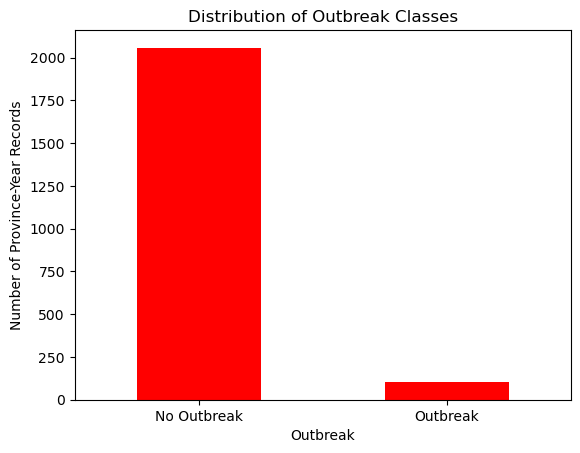

In [33]:
#EDA
#Check Class Distribution

master["Outbreak"].value_counts().plot(kind="bar",color="red")

plt.title("Distribution of Outbreak Classes")
plt.xlabel("Outbreak")
plt.ylabel("Number of Province-Year Records")
plt.xticks([0,1],["No Outbreak","Outbreak"], rotation=0)

plt.show()

In [34]:
#provinces experienced the most outbreaks.
province_counts = (
    master.groupby("Province")["Outbreak"]
    .sum()
    .sort_values(ascending=False)
)

print(province_counts)

Province
Limpopo          32
KwaZulu-Natal    27
Mpumalanga       19
Eastern Cape      7
North West        7
Free State        5
Gauteng           5
Northern Cape     0
Western Cape      0
Name: Outbreak, dtype: int32


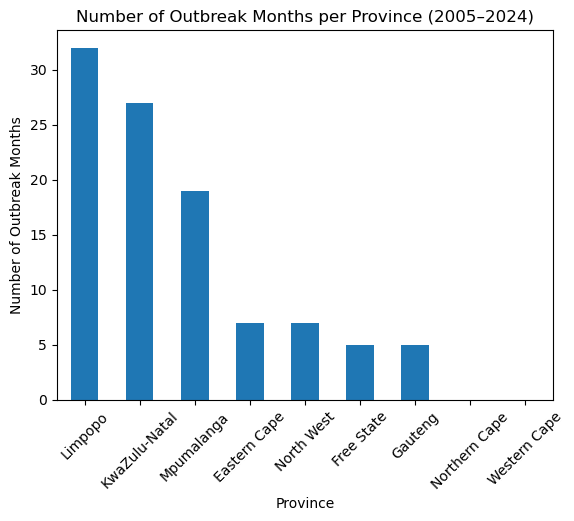

In [35]:
province_counts.plot(kind="bar")

plt.title("Number of Outbreak Months per Province (2005–2024)")
plt.xlabel("Province")
plt.ylabel("Number of Outbreak Months")

plt.xticks(rotation=45)

plt.show()

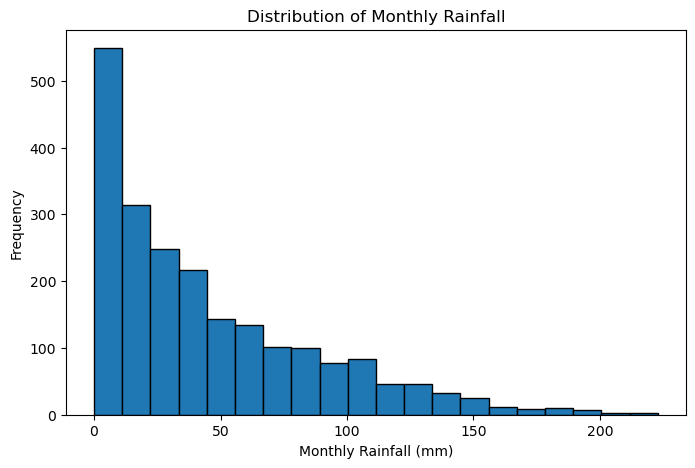

In [36]:
#Rainfall Distribution

plt.figure(figsize=(8,5))

plt.hist(master["Rainfall"], bins=20, edgecolor="black")

plt.title("Distribution of Monthly Rainfall")
plt.xlabel("Monthly Rainfall (mm)")
plt.ylabel("Frequency")

plt.show()

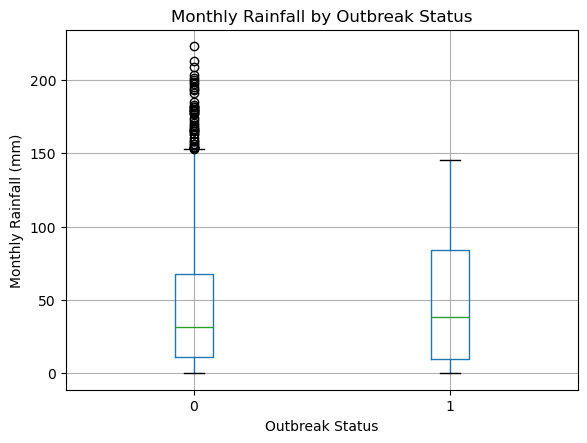

In [37]:
master.boxplot(column="Rainfall", by="Outbreak")

plt.title("Monthly Rainfall by Outbreak Status")
plt.suptitle("")

plt.xlabel("Outbreak Status")
plt.ylabel("Monthly Rainfall (mm)")

plt.show()

In [38]:
#Correlation Matrix
corr = master.drop(columns=["Province"]).corr()

print(corr)

                         Year         Month  Rainfall  National_Cattle  \
Year             1.000000e+00  2.817654e-16 -0.001534    -8.839145e-01   
Month            2.817654e-16  1.000000e+00 -0.076509    -1.112852e-16   
Rainfall        -1.534142e-03 -7.650910e-02  1.000000    -2.068501e-02   
National_Cattle -8.839145e-01 -1.112852e-16 -0.020685     1.000000e+00   
National_Goats  -9.682234e-01 -3.120786e-17  0.002425     9.321313e-01   
National_Sheep  -9.702207e-01 -2.086495e-17 -0.009088     9.630152e-01   
Outbreak_Count   1.309237e-01 -3.009630e-02  0.029524    -1.436547e-01   
Outbreak         1.937989e-01 -1.264532e-03  0.005766    -2.076902e-01   

                 National_Goats  National_Sheep  Outbreak_Count  Outbreak  
Year              -9.682234e-01   -9.702207e-01        0.130924  0.193799  
Month             -3.120786e-17   -2.086495e-17       -0.030096 -0.001265  
Rainfall           2.425123e-03   -9.087984e-03        0.029524  0.005766  
National_Cattle    9.321313e-

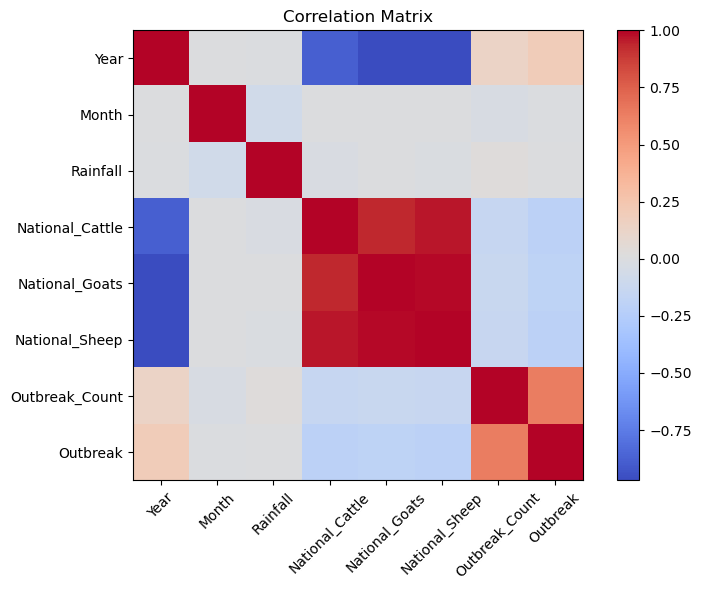

In [39]:
plt.figure(figsize=(8,6))

plt.imshow(corr, cmap="coolwarm", interpolation="nearest")

plt.colorbar()

plt.xticks(range(len(corr.columns)), corr.columns, rotation=45)
plt.yticks(range(len(corr.columns)), corr.columns)

plt.title("Correlation Matrix")

plt.tight_layout()

plt.show()

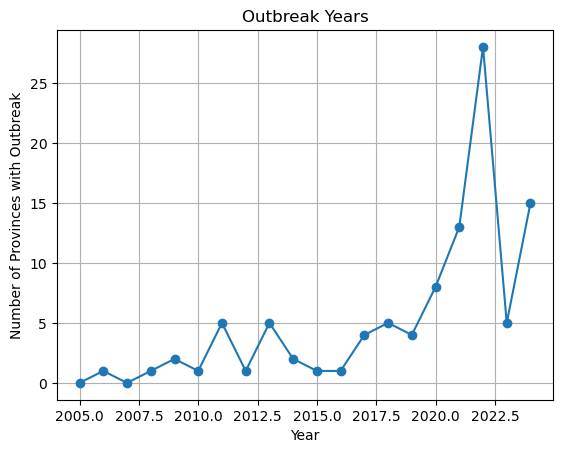

In [40]:
#Outbreaks by Year
year_counts = master.groupby("Year")["Outbreak"].sum()

year_counts.plot(marker="o")

plt.title("Outbreak Years")
plt.xlabel("Year")
plt.ylabel("Number of Provinces with Outbreak")

plt.grid(True)

plt.show()


In [41]:
 #HIGH-RISK PROVINCE ANALYSIS


province_summary = (
    master.groupby("Province")
    .agg(
        Average_Rainfall=("Rainfall", "mean"),
        Average_Cattle=("National_Cattle", "mean"),
        Average_Goats=("National_Goats", "mean"),
        Average_Sheep=("National_Sheep", "mean"),
        Outbreak_Months=("Outbreak", "sum")
    )
)

# Calculate the percentage of outbreak months
province_summary["Risk_Percentage"] = (
    province_summary["Outbreak_Months"] / 240
) * 100

# Sort from highest to lowest risk
province_summary = province_summary.sort_values(
    by="Risk_Percentage",
    ascending=False
)

print(province_summary)

               Average_Rainfall  Average_Cattle  Average_Goats  Average_Sheep  \
Province                                                                        
Limpopo               41.476583      13220837.7      5789760.8    23449719.35   
KwaZulu-Natal         71.279917      13220837.7      5789760.8    23449719.35   
Mpumalanga            58.923333      13220837.7      5789760.8    23449719.35   
Eastern Cape          47.191167      13220837.7      5789760.8    23449719.35   
North West            40.036458      13220837.7      5789760.8    23449719.35   
Free State            46.581708      13220837.7      5789760.8    23449719.35   
Gauteng               51.820833      13220837.7      5789760.8    23449719.35   
Northern Cape         19.640833      13220837.7      5789760.8    23449719.35   
Western Cape          27.889042      13220837.7      5789760.8    23449719.35   

               Outbreak_Months  Risk_Percentage  
Province                                         
Limpopo 

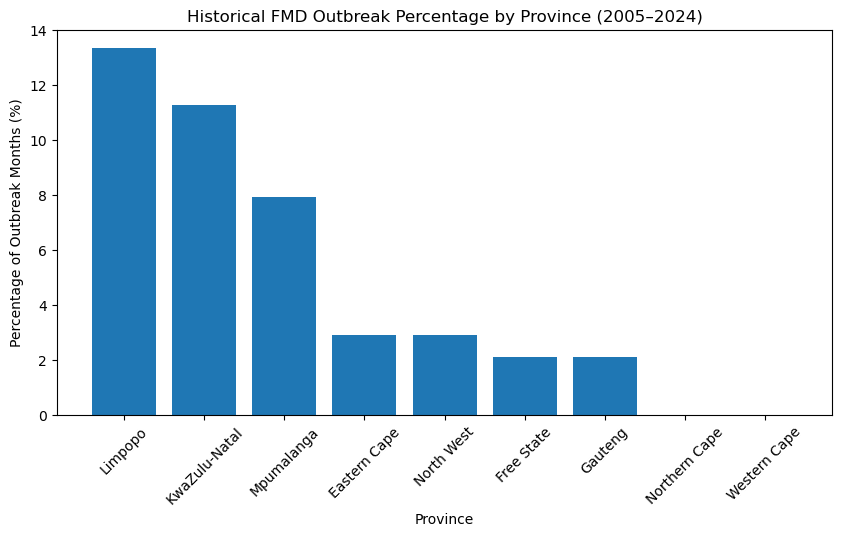

In [42]:
plt.figure(figsize=(10,5))

plt.bar(
    province_summary.index,
    province_summary["Risk_Percentage"]
)

plt.title("Historical FMD Outbreak Percentage by Province (2005–2024)")
plt.xlabel("Province")
plt.ylabel("Percentage of Outbreak Months (%)")

plt.xticks(rotation=45)

plt.show()

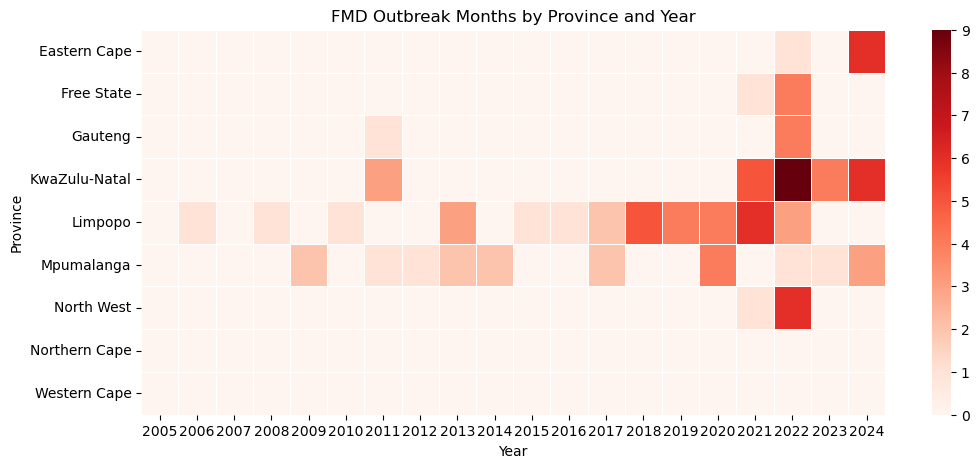

In [43]:
# Creating province-year outbreak table
heatmap_data = master.pivot_table(
    index="Province",
    columns="Year",
    values="Outbreak",
    aggfunc="sum"
)

plt.figure(figsize=(12,5))

sns.heatmap(
    heatmap_data,
    cmap="Reds",
    linewidths=0.5
)

plt.title("FMD Outbreak Months by Province and Year")
plt.xlabel("Year")
plt.ylabel("Province")

plt.show()

In [44]:
#FEATURE ENGINEERING
# Create 3-month rolling rainfall average

master = master.sort_values(
    ['Province', 'Year', 'Month']
)

master['Rainfall_3Month_Avg'] = (
    master.groupby('Province')['Rainfall']
    .transform(
        lambda x: x.rolling(
            window=3,
            min_periods=1
        ).mean()
    )
)

print(
    master[
        ['Province',
         'Year',
         'Month',
         'Rainfall',
         'Rainfall_3Month_Avg']
    ].head(12)
)

        Province  Year  Month  Rainfall  Rainfall_3Month_Avg
0   Eastern Cape  2005      1     97.82            97.820000
1   Eastern Cape  2005      2     81.39            89.605000
2   Eastern Cape  2005      3     65.76            81.656667
3   Eastern Cape  2005      4     52.01            66.386667
4   Eastern Cape  2005      5     24.79            47.520000
5   Eastern Cape  2005      6     12.11            29.636667
6   Eastern Cape  2005      7      2.77            13.223333
7   Eastern Cape  2005      8     15.06             9.980000
8   Eastern Cape  2005      9     11.01             9.613333
9   Eastern Cape  2005     10     27.69            17.920000
10  Eastern Cape  2005     11     98.32            45.673333
11  Eastern Cape  2005     12     36.02            54.010000


In [45]:
# Create previous-month rainfall

master['Rainfall_Lag1'] = (
    master.groupby('Province')['Rainfall']
    .shift(1)
)

print(
    master[
        ['Province',
         'Year',
         'Month',
         'Rainfall',
         'Rainfall_Lag1']
    ].head(12)
)

        Province  Year  Month  Rainfall  Rainfall_Lag1
0   Eastern Cape  2005      1     97.82            NaN
1   Eastern Cape  2005      2     81.39          97.82
2   Eastern Cape  2005      3     65.76          81.39
3   Eastern Cape  2005      4     52.01          65.76
4   Eastern Cape  2005      5     24.79          52.01
5   Eastern Cape  2005      6     12.11          24.79
6   Eastern Cape  2005      7      2.77          12.11
7   Eastern Cape  2005      8     15.06           2.77
8   Eastern Cape  2005      9     11.01          15.06
9   Eastern Cape  2005     10     27.69          11.01
10  Eastern Cape  2005     11     98.32          27.69
11  Eastern Cape  2005     12     36.02          98.32


In [46]:
# Create monthly rainfall change

master['Rainfall_Change'] = (
    master['Rainfall'] - master['Rainfall_Lag1']
)

print(
    master[
        ['Province',
         'Year',
         'Month',
         'Rainfall',
         'Rainfall_Lag1',
         'Rainfall_Change']
    ].head(12)
)

        Province  Year  Month  Rainfall  Rainfall_Lag1  Rainfall_Change
0   Eastern Cape  2005      1     97.82            NaN              NaN
1   Eastern Cape  2005      2     81.39          97.82           -16.43
2   Eastern Cape  2005      3     65.76          81.39           -15.63
3   Eastern Cape  2005      4     52.01          65.76           -13.75
4   Eastern Cape  2005      5     24.79          52.01           -27.22
5   Eastern Cape  2005      6     12.11          24.79           -12.68
6   Eastern Cape  2005      7      2.77          12.11            -9.34
7   Eastern Cape  2005      8     15.06           2.77            12.29
8   Eastern Cape  2005      9     11.01          15.06            -4.05
9   Eastern Cape  2005     10     27.69          11.01            16.68
10  Eastern Cape  2005     11     98.32          27.69            70.63
11  Eastern Cape  2005     12     36.02          98.32           -62.30


In [47]:
# Create previous-month outbreak feature

master['Outbreak_Lag1'] = (
    master.groupby('Province')['Outbreak']
    .shift(1)
)

print(
    master[
        ['Province',
         'Year',
         'Month',
         'Outbreak',
         'Outbreak_Lag1']
    ].head(20)
)

        Province  Year  Month  Outbreak  Outbreak_Lag1
0   Eastern Cape  2005      1         0            NaN
1   Eastern Cape  2005      2         0            0.0
2   Eastern Cape  2005      3         0            0.0
3   Eastern Cape  2005      4         0            0.0
4   Eastern Cape  2005      5         0            0.0
5   Eastern Cape  2005      6         0            0.0
6   Eastern Cape  2005      7         0            0.0
7   Eastern Cape  2005      8         0            0.0
8   Eastern Cape  2005      9         0            0.0
9   Eastern Cape  2005     10         0            0.0
10  Eastern Cape  2005     11         0            0.0
11  Eastern Cape  2005     12         0            0.0
12  Eastern Cape  2006      1         0            0.0
13  Eastern Cape  2006      2         0            0.0
14  Eastern Cape  2006      3         0            0.0
15  Eastern Cape  2006      4         0            0.0
16  Eastern Cape  2006      5         0            0.0
17  Easter

In [48]:
# Create previous 3-month outbreak count

master['Outbreak_3Month_Count'] = (
    master.groupby('Province')['Outbreak']
    .transform(
        lambda x: x.shift(1)
                  .rolling(window=3, min_periods=1)
                  .sum()
    )
)

print(
    master[
        ['Province',
         'Year',
         'Month',
         'Outbreak',
         'Outbreak_Lag1',
         'Outbreak_3Month_Count']
    ].head(20)
)

        Province  Year  Month  Outbreak  Outbreak_Lag1  Outbreak_3Month_Count
0   Eastern Cape  2005      1         0            NaN                    NaN
1   Eastern Cape  2005      2         0            0.0                    0.0
2   Eastern Cape  2005      3         0            0.0                    0.0
3   Eastern Cape  2005      4         0            0.0                    0.0
4   Eastern Cape  2005      5         0            0.0                    0.0
5   Eastern Cape  2005      6         0            0.0                    0.0
6   Eastern Cape  2005      7         0            0.0                    0.0
7   Eastern Cape  2005      8         0            0.0                    0.0
8   Eastern Cape  2005      9         0            0.0                    0.0
9   Eastern Cape  2005     10         0            0.0                    0.0
10  Eastern Cape  2005     11         0            0.0                    0.0
11  Eastern Cape  2005     12         0            0.0          

In [49]:
print(
    master[
        [
            'Rainfall_Lag1',
            'Rainfall_Change',
            'Outbreak_Lag1',
            'Outbreak_3Month_Count'
        ]
    ].isna().sum()
)

Rainfall_Lag1            9
Rainfall_Change          9
Outbreak_Lag1            9
Outbreak_3Month_Count    9
dtype: int64


In [50]:
master = master.dropna(
    subset=[
        'Rainfall_Lag1',
        'Rainfall_Change',
        'Outbreak_Lag1',
        'Outbreak_3Month_Count'
    ]
).reset_index(drop=True)

In [51]:
print("New shape:", master.shape)

print("\nMissing values:")
print(
    master[
        [
            'Rainfall_Lag1',
            'Rainfall_Change',
            'Outbreak_Lag1',
            'Outbreak_3Month_Count'
        ]
    ].isna().sum()
)

New shape: (2151, 14)

Missing values:
Rainfall_Lag1            0
Rainfall_Change          0
Outbreak_Lag1            0
Outbreak_3Month_Count    0
dtype: int64


In [52]:
# encoding month cyclically using sine/cosine so the model understands months as repeating cycles 
import numpy as np

master['Month_Sin'] = np.sin(
    2 * np.pi * master['Month'] / 12
)

master['Month_Cos'] = np.cos(
    2 * np.pi * master['Month'] / 12
)
print(
    master[
        ['Month', 'Month_Sin', 'Month_Cos']
    ].head(12)
)

    Month     Month_Sin     Month_Cos
0       2  8.660254e-01  5.000000e-01
1       3  1.000000e+00  6.123234e-17
2       4  8.660254e-01 -5.000000e-01
3       5  5.000000e-01 -8.660254e-01
4       6  1.224647e-16 -1.000000e+00
5       7 -5.000000e-01 -8.660254e-01
6       8 -8.660254e-01 -5.000000e-01
7       9 -1.000000e+00 -1.836970e-16
8      10 -8.660254e-01  5.000000e-01
9      11 -5.000000e-01  8.660254e-01
10     12 -2.449294e-16  1.000000e+00
11      1  5.000000e-01  8.660254e-01


In [53]:
# 1. Defining the risk levels based on geography
# Limpopo, Mpumalanga, and KZN are "Red Line" zones (High Risk = 3)
# North West and Gauteng are transit hubs (Medium Risk = 2)
# The rest are lower risk (1)

wildlife_risk_map = {
    'Limpopo': 3,
    'Mpumalanga': 3,
    'KwaZulu-Natal': 3,
    'North West': 2,
    'Gauteng': 2,
    'Free State': 1,
    'Eastern Cape': 1,
    'Western Cape': 1,
    'Northern Cape': 1
}

# 2. Mapping this to the master dataframe
master['Wildlife_Proximity_Score'] = master['Province'].map(wildlife_risk_map)

# Checking if it worked
print(master[['Province', 'Wildlife_Proximity_Score']].drop_duplicates())


           Province  Wildlife_Proximity_Score
0      Eastern Cape                         1
239      Free State                         1
478         Gauteng                         2
717   KwaZulu-Natal                         3
956         Limpopo                         3
1195     Mpumalanga                         3
1434     North West                         2
1673  Northern Cape                         1
1912   Western Cape                         1


In [54]:
 #1. Defining the borders 
neighbors = {
    'Gauteng': ['North West', 'Mpumalanga', 'Free State', 'Limpopo'],
    'Limpopo': ['North West', 'Gauteng', 'Mpumalanga'],
    'Mpumalanga': ['Limpopo', 'Gauteng', 'Free State', 'KwaZulu-Natal'],
    'KwaZulu-Natal': ['Mpumalanga', 'Free State', 'Eastern Cape'],
    'Free State': ['Gauteng', 'Mpumalanga', 'KwaZulu-Natal', 'Eastern Cape', 'Northern Cape', 'North West'],
    'Eastern Cape': ['Western Cape', 'Northern Cape', 'Free State', 'KwaZulu-Natal'],
    'Western Cape': ['Northern Cape', 'Eastern Cape'],
    'Northern Cape': ['Western Cape', 'Eastern Cape', 'Free State', 'North West'],
    'North West': ['Northern Cape', 'Free State', 'Gauteng', 'Limpopo']
}

# 2. Create a function to calculate neighbor risk
#  and ensuring sure the data is chronologically ordered
master = master.sort_values(
    ['Province', 'Year', 'Month']
).reset_index(drop=True)


# Calculating the number of outbreaks occurring in neighbouring
# provinces during each province-month
def get_neighbor_outbreak_count(row):
    
    province = row['Province']
    year = row['Year']
    month = row['Month']
    
    # Provinces bordering the current province
    my_neighbors = neighbors.get(province, [])
    
    # Outbreaks in neighbouring provinces during this month
    neighbor_data = master[
        (master['Province'].isin(my_neighbors)) &
        (master['Year'] == year) &
        (master['Month'] == month)
    ]
    
    return neighbor_data['Outbreak'].sum()


master['Neighbor_Outbreak_Count'] = master.apply(
    get_neighbor_outbreak_count,
    axis=1
)



# therefore Shift by one month WITHIN each province.

master['Neighbor_Outbreak_Lag1'] = (
    master.groupby('Province')['Neighbor_Outbreak_Count']
    .shift(1)
)


# The first month for each province has no previous month.
# Set that missing value to 0.
master['Neighbor_Outbreak_Lag1'] = (
    master['Neighbor_Outbreak_Lag1']
    .fillna(0)
)


print(
    master[
        [
            'Province',
            'Year',
            'Month',
            'Neighbor_Outbreak_Count',
            'Neighbor_Outbreak_Lag1'
        ]
    ].head(20)
)

        Province  Year  Month  Neighbor_Outbreak_Count  Neighbor_Outbreak_Lag1
0   Eastern Cape  2005      2                        0                     0.0
1   Eastern Cape  2005      3                        0                     0.0
2   Eastern Cape  2005      4                        0                     0.0
3   Eastern Cape  2005      5                        0                     0.0
4   Eastern Cape  2005      6                        0                     0.0
5   Eastern Cape  2005      7                        0                     0.0
6   Eastern Cape  2005      8                        0                     0.0
7   Eastern Cape  2005      9                        0                     0.0
8   Eastern Cape  2005     10                        0                     0.0
9   Eastern Cape  2005     11                        0                     0.0
10  Eastern Cape  2005     12                        0                     0.0
11  Eastern Cape  2006      1                       

In [55]:
feature_columns = [
    'Rainfall',
    'National_Cattle',
    'National_Goats',
    'National_Sheep',
    'Rainfall_3Month_Avg',
    'Rainfall_Lag1',
    'Rainfall_Change',
    'Outbreak_Lag1',
    'Outbreak_3Month_Count',
    'Month_Sin',
    'Month_Cos',
    'Wildlife_Proximity_Score',
    'Neighbor_Outbreak_Lag1'
]

In [56]:
#machine learning
X = master[feature_columns].copy()
y = master['Outbreak'].copy()

print("X shape:", X.shape)
print("Any missing values", X.isna().sum().sum())
train_data = master[master['Year'] <= 2020].copy()
test_data = master[master['Year'] >= 2021].copy()



X shape: (2151, 13)
Any missing values 0


In [57]:
train_mask = master['Year'] <= 2020
test_mask = master['Year'] >= 2021

X_train = X.loc[train_mask].copy()
X_test  = X.loc[test_mask].copy()

y_train = y.loc[train_mask].copy()
y_test  = y.loc[test_mask].copy()


print("Training shape:", X_train.shape)
print("Testing shape :", X_test.shape)

print("\nTraining years:")
print(master.loc[train_mask, 'Year'].min(),
      "to",
      master.loc[train_mask, 'Year'].max())

print("\nTesting years:")
print(master.loc[test_mask, 'Year'].min(),
      "to",
      master.loc[test_mask, 'Year'].max())

print("\nTraining target:")
print(y_train.value_counts())

print("\nTesting target:")
print(y_test.value_counts())

print("\nMissing values:")
print(X_train.isna().sum())
print(X_test.isna().sum())

Training shape: (1719, 13)
Testing shape : (432, 13)

Training years:
2005 to 2020

Testing years:
2021 to 2024

Training target:
Outbreak
0    1678
1      41
Name: count, dtype: int64

Testing target:
Outbreak
0    371
1     61
Name: count, dtype: int64

Missing values:
Rainfall                    0
National_Cattle             0
National_Goats              0
National_Sheep              0
Rainfall_3Month_Avg         0
Rainfall_Lag1               0
Rainfall_Change             0
Outbreak_Lag1               0
Outbreak_3Month_Count       0
Month_Sin                   0
Month_Cos                   0
Wildlife_Proximity_Score    0
Neighbor_Outbreak_Lag1      0
dtype: int64
Rainfall                    0
National_Cattle             0
National_Goats              0
National_Sheep              0
Rainfall_3Month_Avg         0
Rainfall_Lag1               0
Rainfall_Change             0
Outbreak_Lag1               0
Outbreak_3Month_Count       0
Month_Sin                   0
Month_Cos                

In [58]:
# split training data(2005-2020) further into smaller training subset(80%) and validation subset (20%), used to select a classification threshold 
from sklearn.model_selection import train_test_split

# ============================================================
# TRAIN / VALIDATION SPLIT
# ============================================================

X_train_model, X_val, y_train_model, y_val = train_test_split(
    X_train,
    y_train,
    test_size=0.20,
    stratify=y_train,
    random_state=42
)

print("Model training:", X_train_model.shape)
print("Validation    :", X_val.shape)

print("\nTraining target:")
print(y_train_model.value_counts())

print("\nValidation target:")
print(y_val.value_counts())

Model training: (1375, 13)
Validation    : (344, 13)

Training target:
Outbreak
0    1342
1      33
Name: count, dtype: int64

Validation target:
Outbreak
0    336
1      8
Name: count, dtype: int64


In [59]:
# ============================================================
# IMPORTING MODELS AND METRICS
# ============================================================

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

import pandas as pd


# ============================================================
# XGBOOST CLASS WEIGHT
# ============================================================

weight = (
    (y_train == 0).sum() /
    (y_train == 1).sum()
)

print("XGBoost scale_pos_weight:", weight)


# ============================================================
# DEFINING MODELS
# ============================================================

models = {

    "Logistic Regression": LogisticRegression(
        class_weight='balanced',
        max_iter=1000,
        random_state=42
    ),

    "Decision Tree": DecisionTreeClassifier(
        class_weight='balanced',
        max_depth=5,
        random_state=42
    ),

    "Random Forest": RandomForestClassifier(
        n_estimators=200,
        class_weight='balanced',
        random_state=42,
        n_jobs=-1
    ),

    "XGBoost": XGBClassifier(
        n_estimators=150,
        max_depth=4,
        learning_rate=0.05,
        scale_pos_weight=weight,
        random_state=42,
        eval_metric='logloss'
    )
}


# ============================================================
# TRAINING MODELS
# ============================================================

results = []

probabilities = {}
predictions = {}

for name, model in models.items():

    print("\nTraining:", name)

    # Train only using training data
    model.fit(X_train, y_train)

    # Probability of outbreak
    y_prob = model.predict_proba(X_test)[:, 1]

    # Initial threshold = 0.50
    y_pred = (y_prob >= 0.50).astype(int)

    # Save probabilities and predictions
    probabilities[name] = y_prob
    predictions[name] = y_pred

    # Metrics
    accuracy = accuracy_score(y_test, y_pred)

    precision = precision_score(
        y_test,
        y_pred,
        zero_division=0
    )

    recall = recall_score(
        y_test,
        y_pred,
        zero_division=0
    )

    f1 = f1_score(
        y_test,
        y_pred,
        zero_division=0
    )

    roc_auc = roc_auc_score(
        y_test,
        y_prob
    )

    results.append({
        'Model': name,
        'Accuracy': round(accuracy, 3),
        'Precision': round(precision, 3),
        'Recall': round(recall, 3),
        'F1 Score': round(f1, 3),
        'ROC-AUC': round(roc_auc, 3)
    })


comparison_df = pd.DataFrame(results)

print("\n================ MODEL COMPARISON ================")
print(comparison_df)

XGBoost scale_pos_weight: 40.926829268292686

Training: Logistic Regression

Training: Decision Tree

Training: Random Forest

Training: XGBoost

================ MODEL COMPARISON ================
                 Model  Accuracy  Precision  Recall  F1 Score  ROC-AUC
0  Logistic Regression     0.711      0.300   0.787     0.434    0.815
1        Decision Tree     0.792      0.325   0.443     0.375    0.651
2        Random Forest     0.861      0.545   0.098     0.167    0.822
3              XGBoost     0.847      0.455   0.410     0.431    0.747



Logistic Regression
[[259 112]
 [ 13  48]]


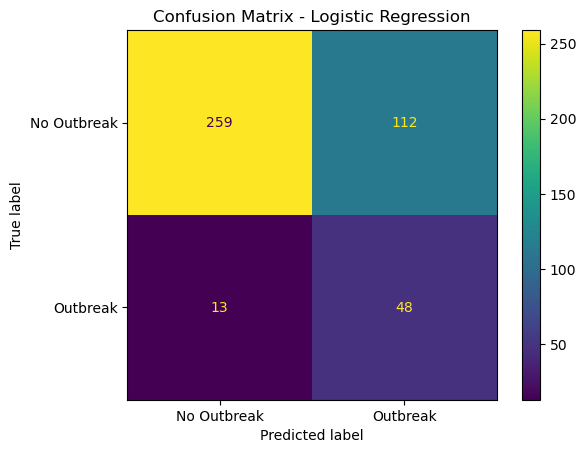


Decision Tree
[[315  56]
 [ 34  27]]


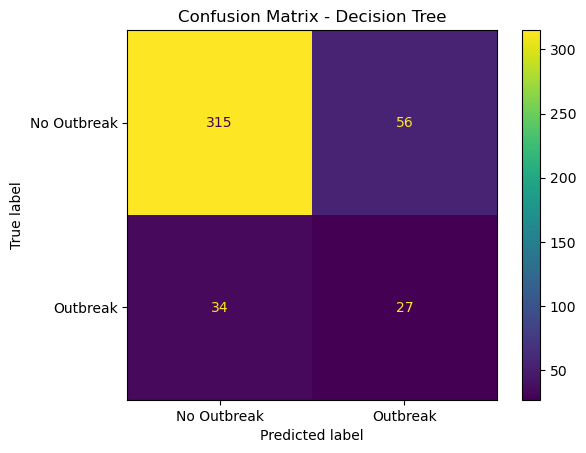


Random Forest
[[366   5]
 [ 55   6]]


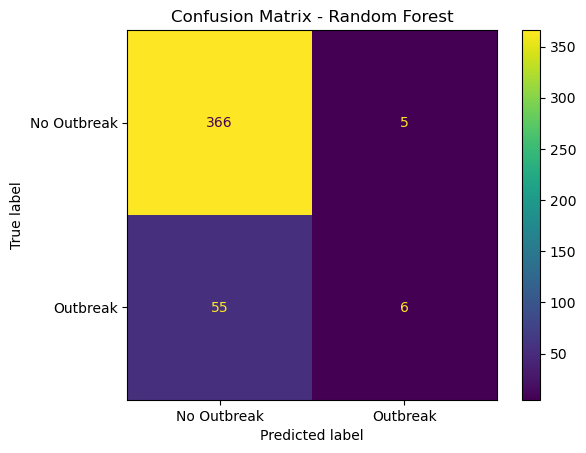


XGBoost
[[341  30]
 [ 36  25]]


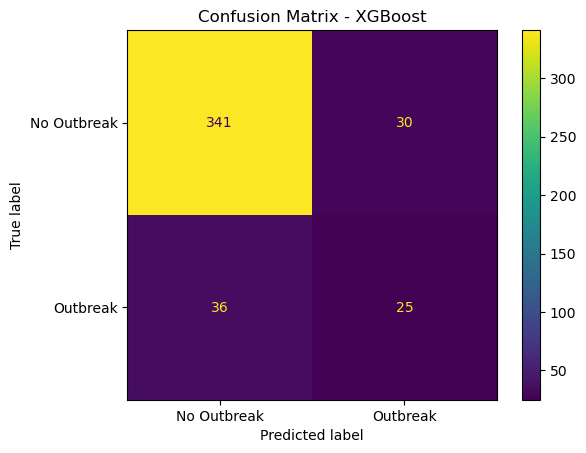

In [60]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

# ============================================================
# CONFUSION MATRICES FOR ALL MODELS
# ============================================================

for name, model in models.items():

    # Get probabilities
    y_prob = model.predict_proba(X_test)[:, 1]

    # Normal 0.50 threshold
    y_pred = (y_prob >= 0.50).astype(int)

    # Confusion matrix
    cm = confusion_matrix(y_test, y_pred)

    print("\n====================================")
    print(name)
    print("====================================")
    print(cm)

    # Display
    disp = ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=['No Outbreak', 'Outbreak']
    )

    disp.plot()
    plt.title(f'Confusion Matrix - {name}')
    plt.show()

In [61]:
# ============================================================
# TRAIN LOGISTIC REGRESSION ON TRAINING SUBSET
# ============================================================

lr_validation_model = LogisticRegression(
    class_weight='balanced',
    max_iter=1000,
    random_state=42
)

lr_validation_model.fit(
    X_train_model,
    y_train_model
)


# Probability predictions on validation data
y_prob_val = lr_validation_model.predict_proba(X_val)[:, 1]


# ============================================================
# TEST DIFFERENT THRESHOLDS
# ============================================================

threshold_results = []

thresholds = [
    0.10,
    0.15,
    0.20,
    0.25,
    0.30,
    0.35,
    0.40,
    0.45,
    0.50
]


for threshold in thresholds:

    y_pred_val = (
        y_prob_val >= threshold
    ).astype(int)

    precision = precision_score(
        y_val,
        y_pred_val,
        zero_division=0
    )

    recall = recall_score(
        y_val,
        y_pred_val,
        zero_division=0
    )

    f1 = f1_score(
        y_val,
        y_pred_val,
        zero_division=0
    )

    threshold_results.append({
        'Threshold': threshold,
        'Precision': round(precision, 3),
        'Recall': round(recall, 3),
        'F1 Score': round(f1, 3)
    })


threshold_df = pd.DataFrame(threshold_results)

print(threshold_df)

   Threshold  Precision  Recall  F1 Score
0       0.10      0.052     1.0     0.099
1       0.15      0.065     1.0     0.121
2       0.20      0.072     1.0     0.134
3       0.25      0.072     1.0     0.134
4       0.30      0.072     1.0     0.134
5       0.35      0.074     1.0     0.138
6       0.40      0.075     1.0     0.140
7       0.45      0.081     1.0     0.150
8       0.50      0.095     1.0     0.174


In [62]:
# ============================================================
# SELECTING THRESHOLD WITH HIGHEST VALIDATION F1
# ============================================================

best_row = threshold_df.loc[
    threshold_df['F1 Score'].idxmax()
]

best_threshold = best_row['Threshold']

print("Best threshold:", best_threshold)
print("Validation Precision:", best_row['Precision'])
print("Validation Recall   :", best_row['Recall'])
print("Validation F1       :", best_row['F1 Score'])

Best threshold: 0.5
Validation Precision: 0.095
Validation Recall   : 1.0
Validation F1       : 0.174


In [63]:
# ============================================================
# FINAL LOGISTIC REGRESSION
# ============================================================

final_lr = LogisticRegression(
    class_weight='balanced',
    max_iter=1000,
    random_state=42
)

final_lr.fit(
    X_train,
    y_train
)


# Predict probabilities on the untouched 2021–2024 test set
y_prob_final_lr = final_lr.predict_proba(X_test)[:, 1]


# Apply threshold selected from validation data
y_pred_final_lr = (
    y_prob_final_lr >= best_threshold
).astype(int)

In [64]:
# ============================================================
# FINAL TEST PERFORMANCE
# ============================================================

print("========== FINAL LOGISTIC REGRESSION ==========")

print(
    "Accuracy :",
    round(
        accuracy_score(y_test, y_pred_final_lr),
        3
    )
)

print(
    "Precision:",
    round(
        precision_score(
            y_test,
            y_pred_final_lr,
            zero_division=0
        ),
        3
    )
)

print(
    "Recall   :",
    round(
        recall_score(
            y_test,
            y_pred_final_lr,
            zero_division=0
        ),
        3
    )
)

print(
    "F1 Score :",
    round(
        f1_score(
            y_test,
            y_pred_final_lr,
            zero_division=0
        ),
        3
    )
)

print(
    "ROC-AUC  :",
    round(
        roc_auc_score(
            y_test,
            y_prob_final_lr
        ),
        3
    )
)

========== FINAL LOGISTIC REGRESSION ==========
Accuracy : 0.711
Precision: 0.3
Recall   : 0.787
F1 Score : 0.434
ROC-AUC  : 0.815


In [65]:
# ============================================================
# LOGISTIC REGRESSION FEATURE IMPORTANCE 
# ============================================================
lr_model = LogisticRegression(
    class_weight='balanced',
    max_iter=1000,
    random_state=42
)
lr_model.fit(X_train, y_train)

lr_importance = pd.DataFrame({
    'Feature': X_train.columns,
    'Coefficient': lr_model.coef_[0]
})

# Sort by absolute value, since negative coefficients matter too
lr_importance['Abs_Coefficient'] = lr_importance['Coefficient'].abs()
lr_importance = lr_importance.sort_values('Abs_Coefficient', ascending=False)

print(lr_importance[['Feature', 'Coefficient']])

                     Feature  Coefficient
11  Wildlife_Proximity_Score     2.502217
8      Outbreak_3Month_Count     1.538078
7              Outbreak_Lag1     0.738240
9                  Month_Sin    -0.338731
12    Neighbor_Outbreak_Lag1    -0.145086
10                 Month_Cos     0.052172
4        Rainfall_3Month_Avg     0.009424
0                   Rainfall    -0.006631
5              Rainfall_Lag1    -0.004113
6            Rainfall_Change    -0.002517
2             National_Goats     0.000003
3             National_Sheep    -0.000002
1            National_Cattle     0.000001


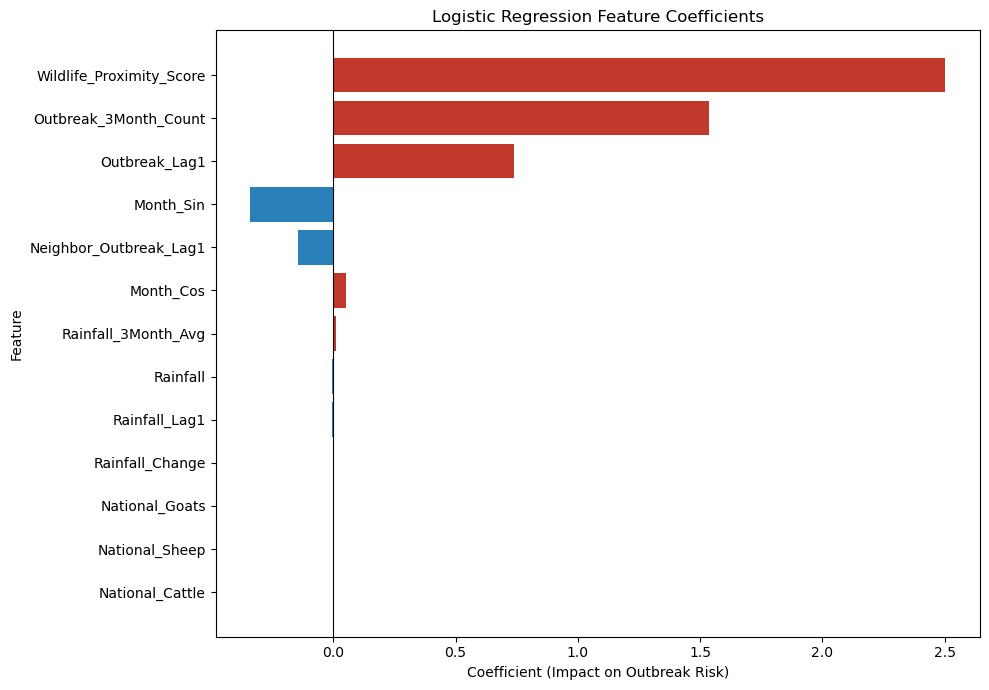

In [66]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 7))
colors = ['#c0392b' if c > 0 else '#2980b9' for c in lr_importance['Coefficient']]
plt.barh(lr_importance['Feature'], lr_importance['Coefficient'], color=colors)
plt.xlabel('Coefficient (Impact on Outbreak Risk)')
plt.ylabel('Feature')
plt.title('Logistic Regression Feature Coefficients')
plt.gca().invert_yaxis()
plt.axvline(x=0, color='black', linewidth=0.8)
plt.tight_layout()
plt.show()

In [67]:
# Taking the most recent available month for every province
latest_month = master.groupby('Province').apply(lambda x: x.sort_values(['Year','Month']).iloc[-1])

X_latest = latest_month[feature_columns].copy()

# Use logistoc regression
risk_scores = lr_model.predict_proba(X_latest)[:, 1]

risk_table = pd.DataFrame({
    'Province': latest_month['Province'],
    'Predicted_Outbreak_Risk': risk_scores
}).sort_values('Predicted_Outbreak_Risk', ascending=False)

print(risk_table)

                    Province  Predicted_Outbreak_Risk
Province                                             
KwaZulu-Natal  KwaZulu-Natal                 0.991112
Limpopo              Limpopo                 0.670764
Mpumalanga        Mpumalanga                 0.655830
North West        North West                 0.170820
Gauteng              Gauteng                 0.153679
Eastern Cape    Eastern Cape                 0.081038
Western Cape    Western Cape                 0.019964
Northern Cape  Northern Cape                 0.018211
Free State        Free State                 0.018121
